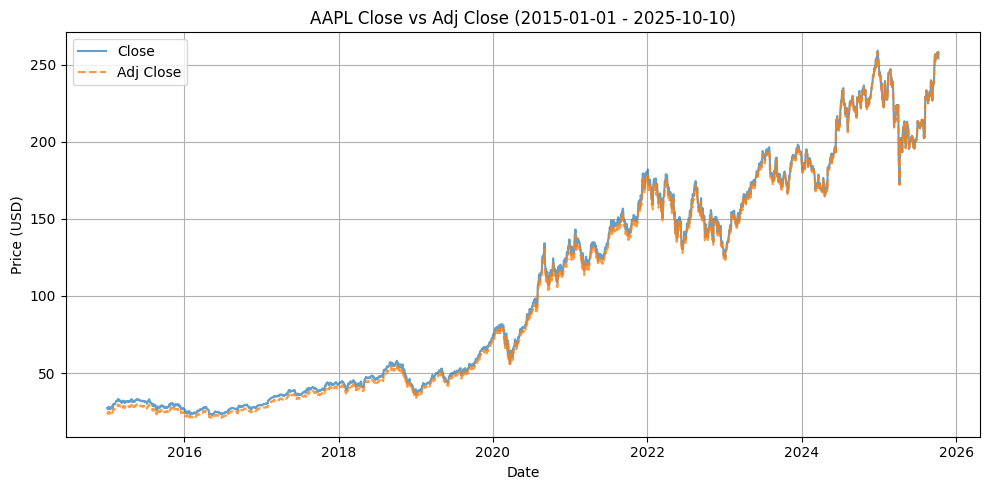

Exception ignored in: <function ZipFile.__del__ at 0x7ad177596840>
Traceback (most recent call last):
  File "/usr/lib/python3.12/zipfile/__init__.py", line 1966, in __del__
    self.close()
  File "/usr/lib/python3.12/zipfile/__init__.py", line 1983, in close
    self.fp.seek(self.start_dir)
ValueError: seek of closed file
Exception ignored in: <function ZipFile.__del__ at 0x7ad177596840>
Traceback (most recent call last):
  File "/usr/lib/python3.12/zipfile/__init__.py", line 1966, in __del__
    self.close()
  File "/usr/lib/python3.12/zipfile/__init__.py", line 1983, in close
    self.fp.seek(self.start_dir)
ValueError: seek of closed file


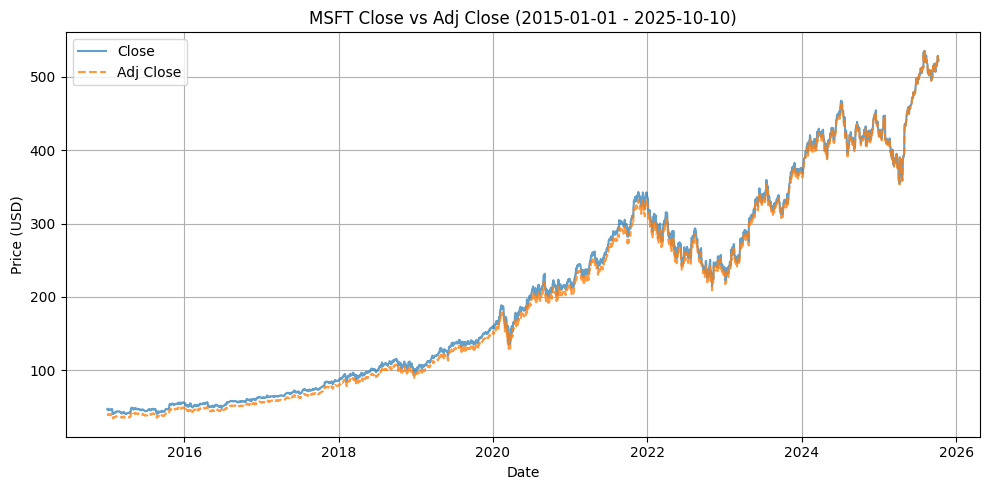

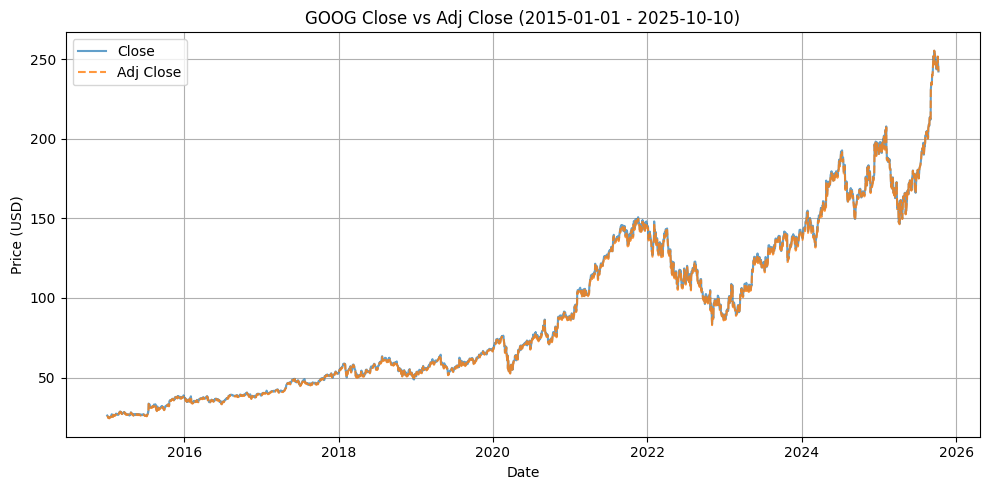

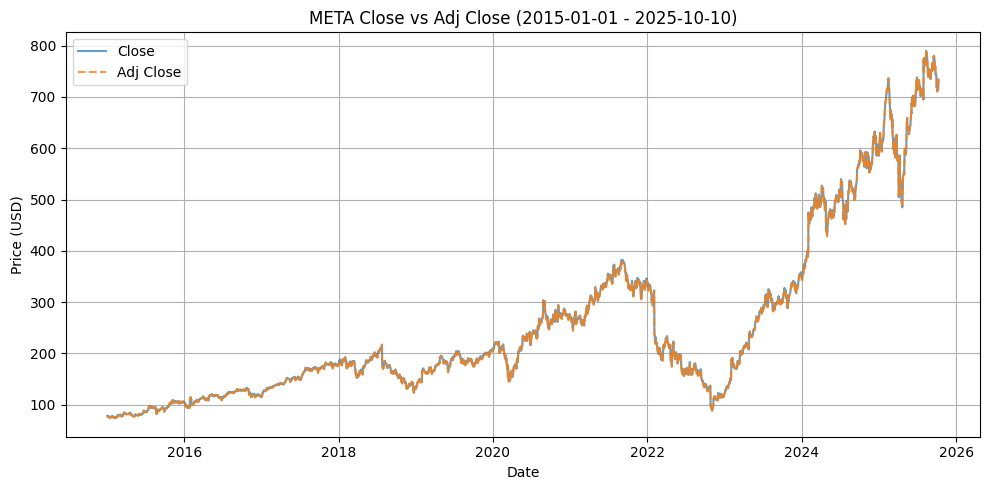

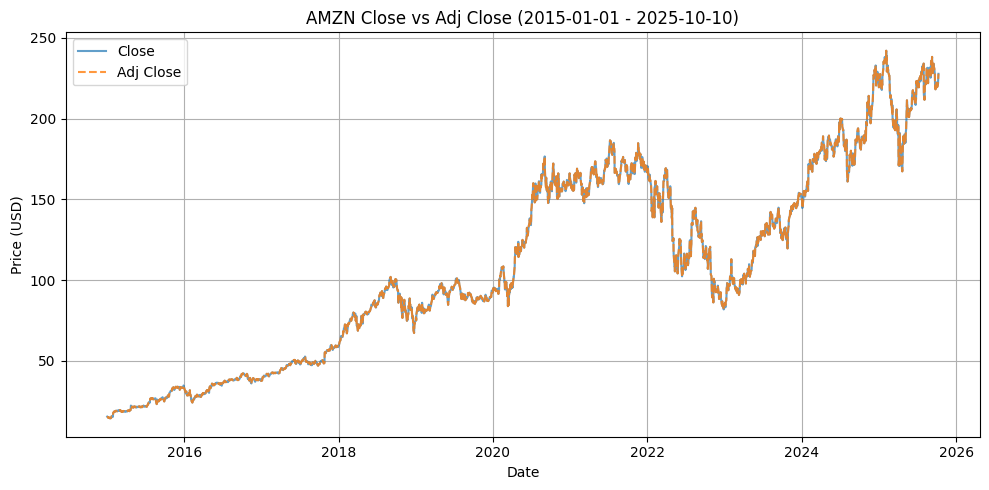

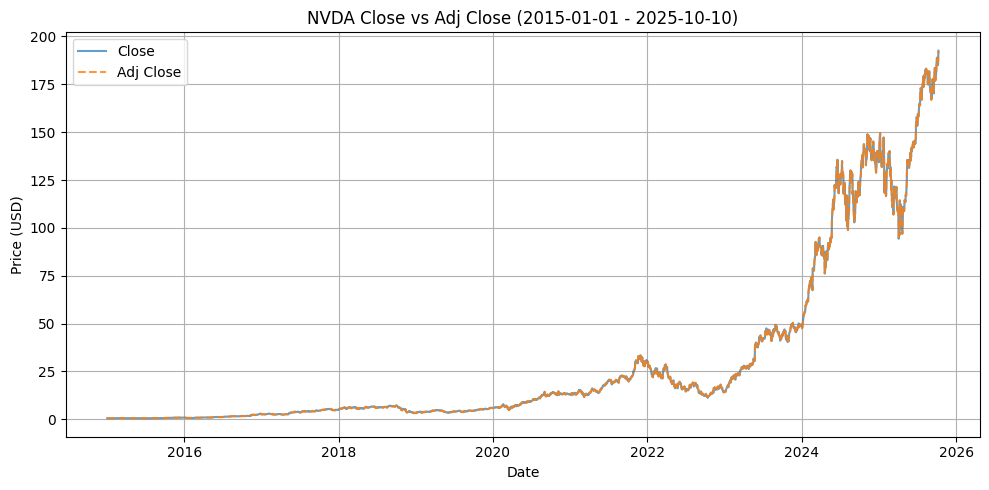

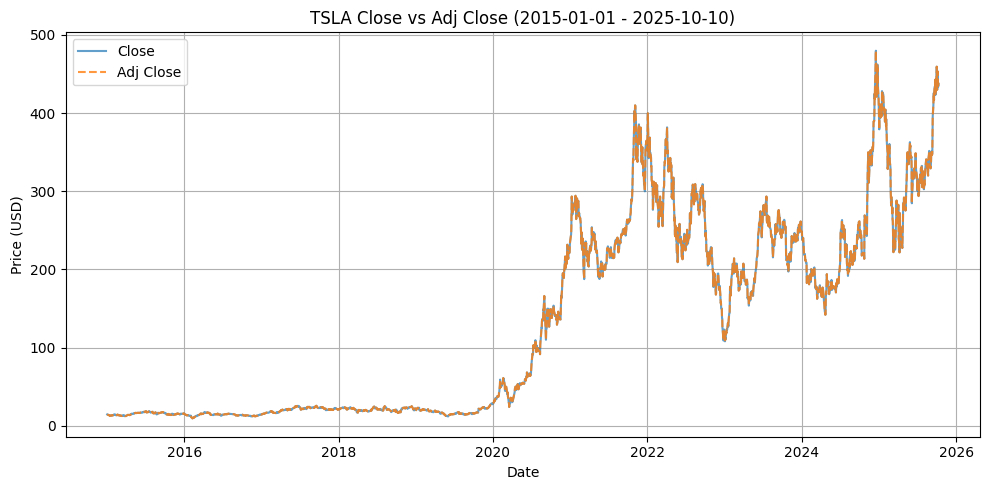

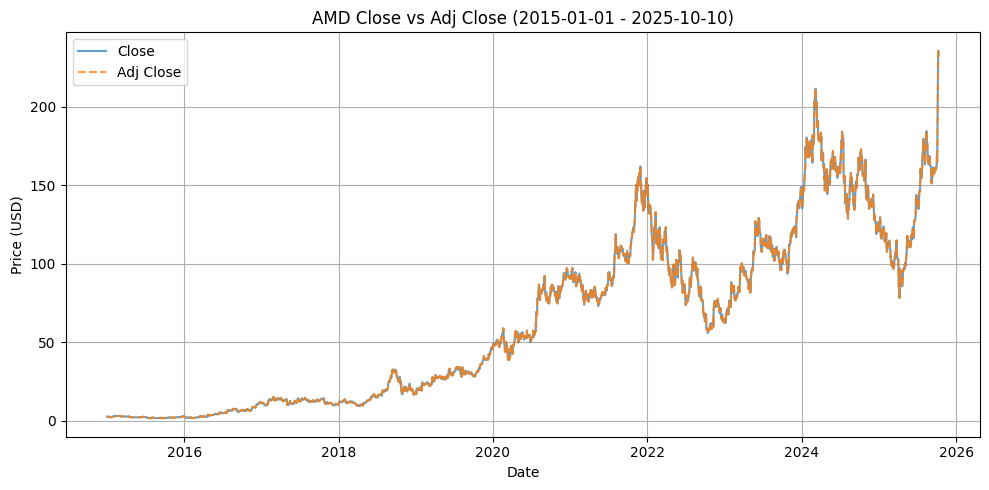

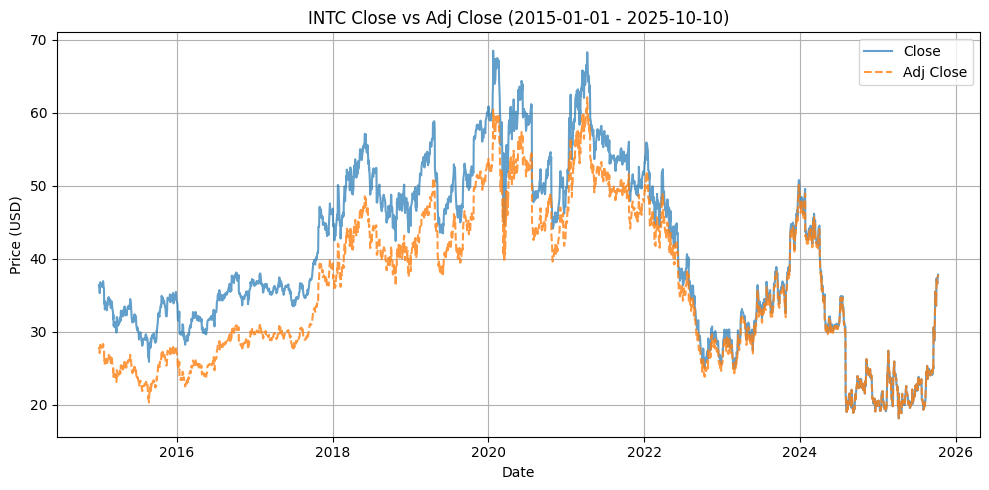

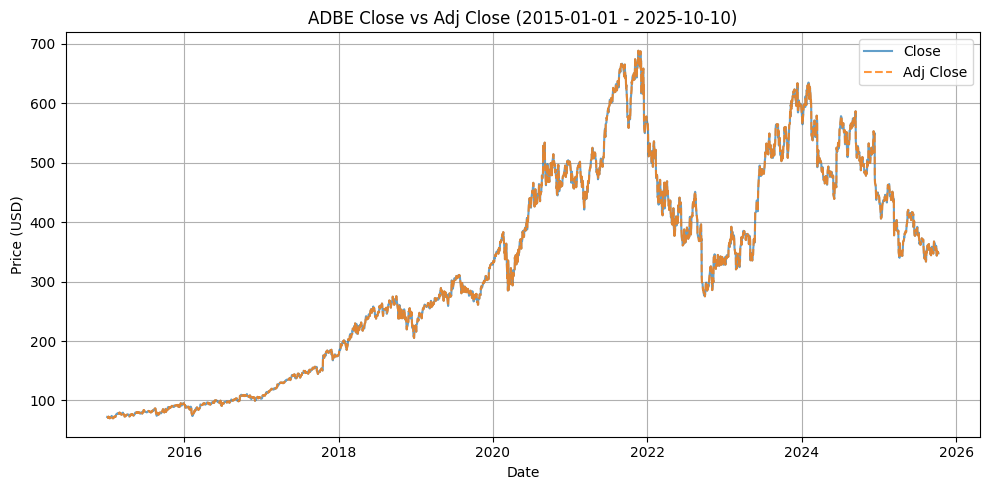

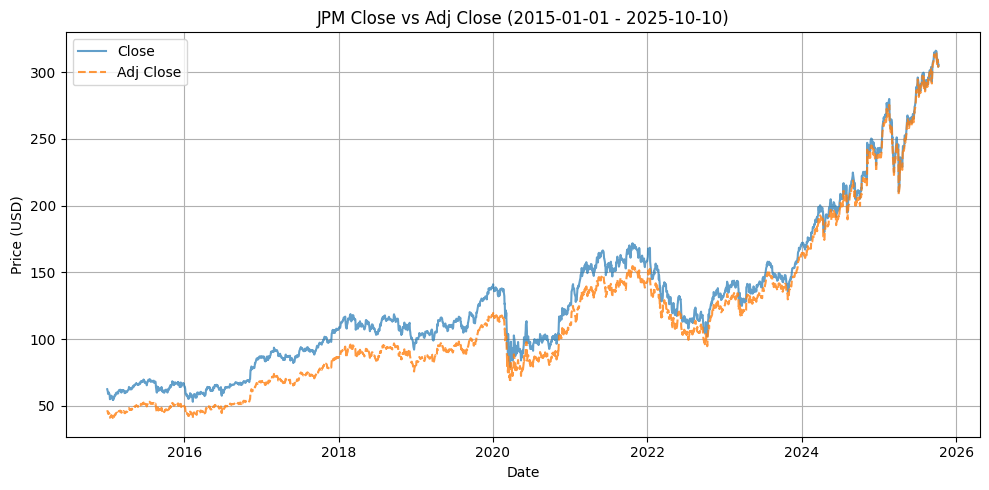

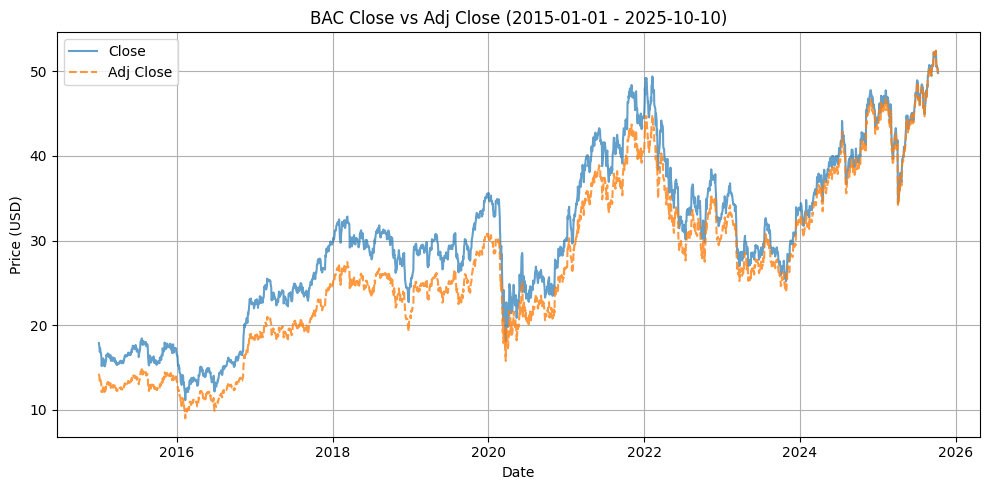

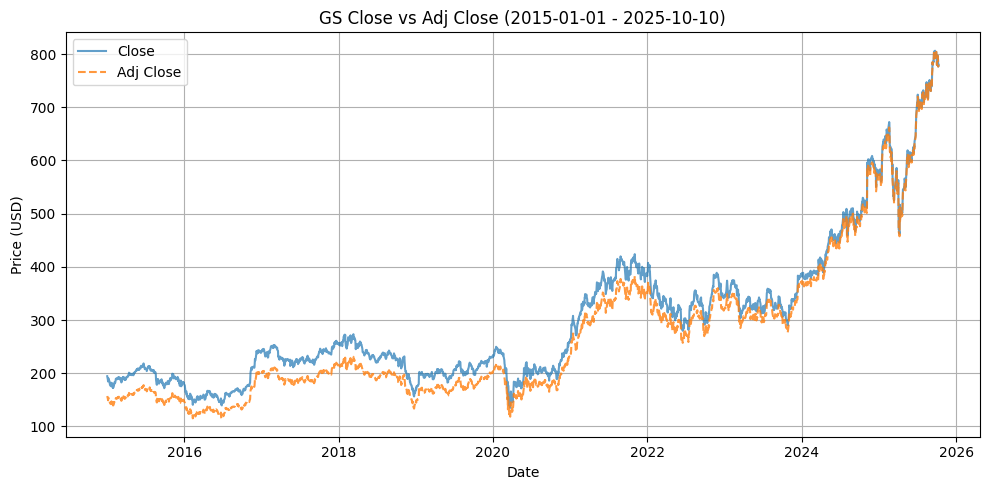

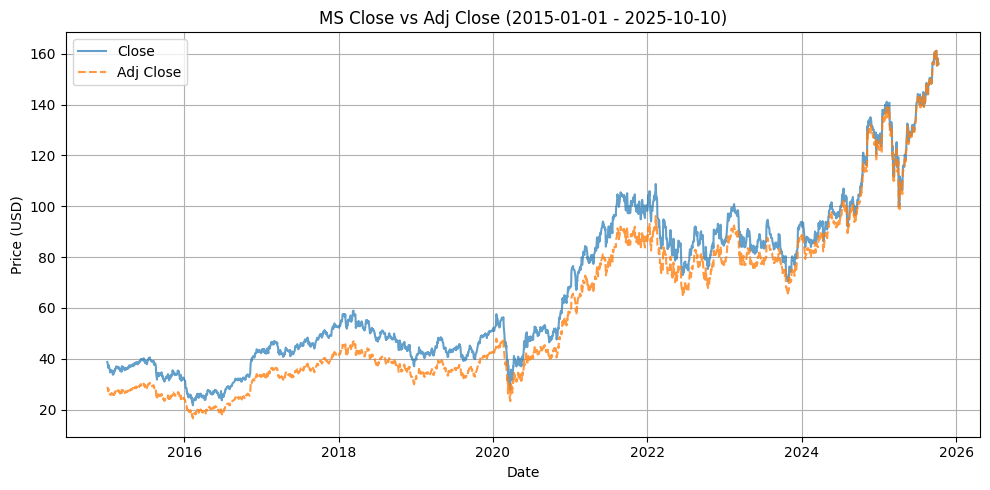

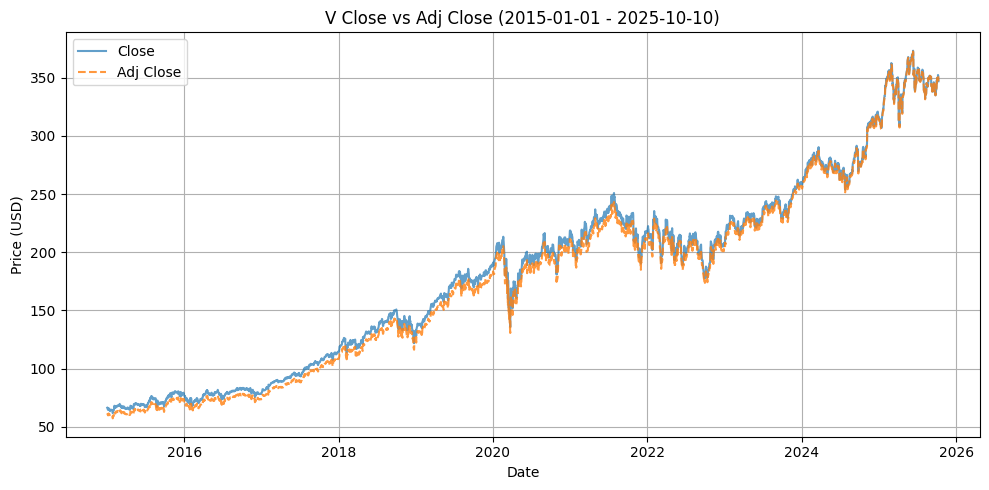

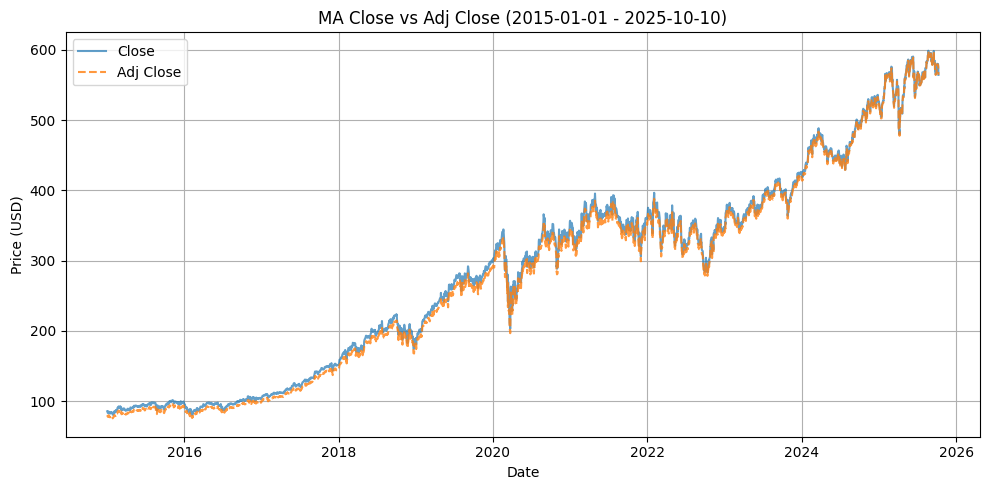

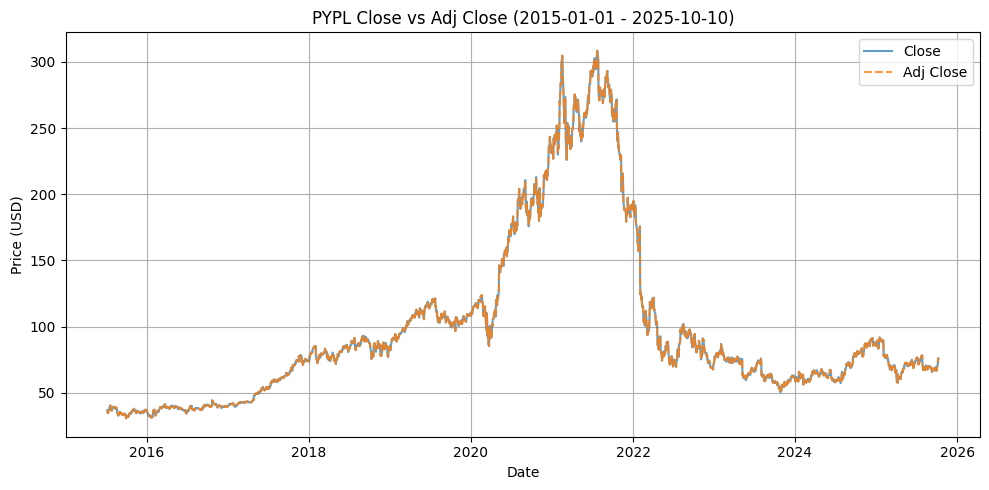

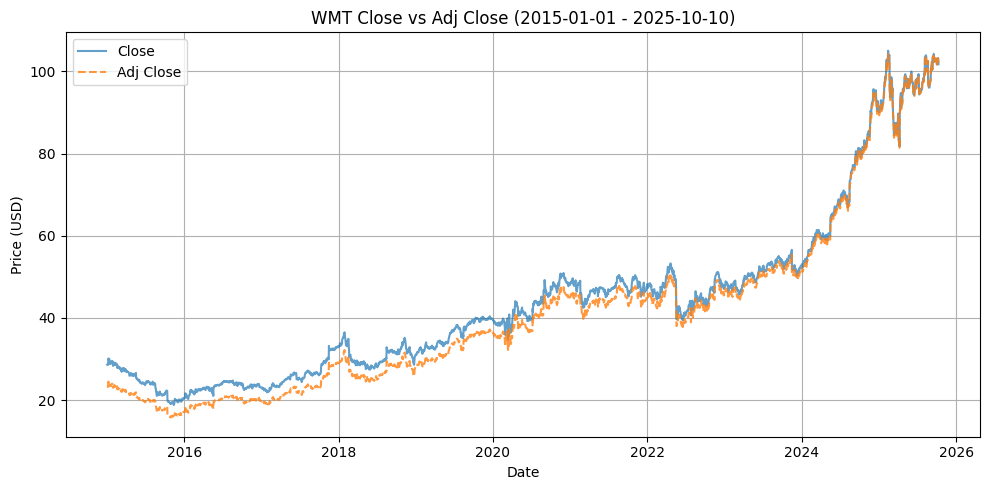

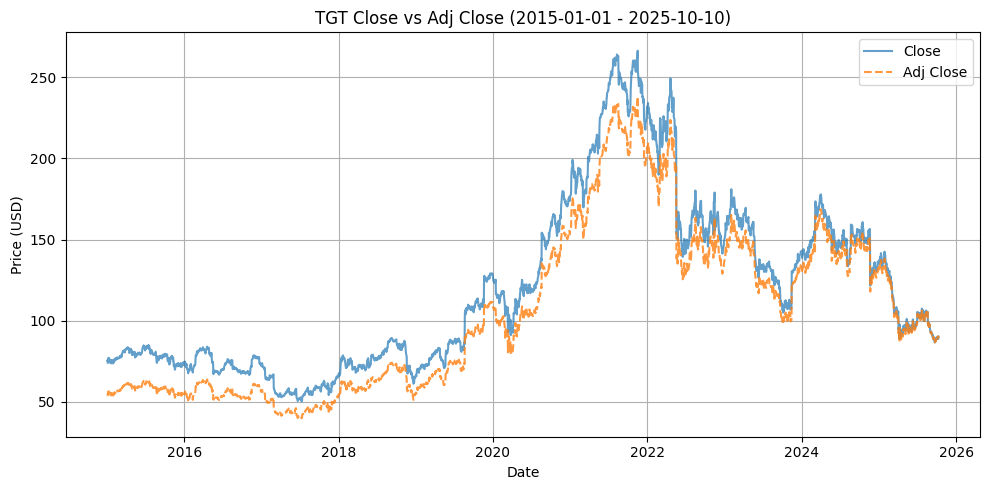

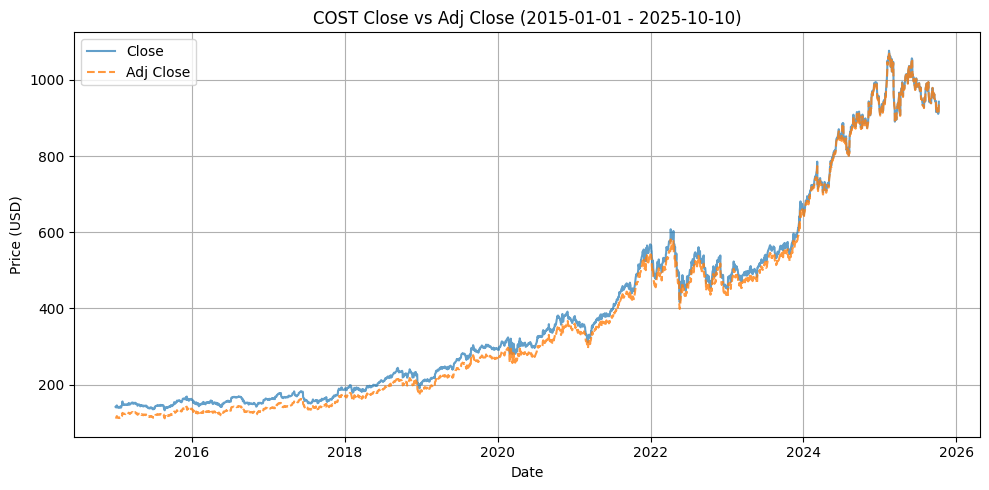

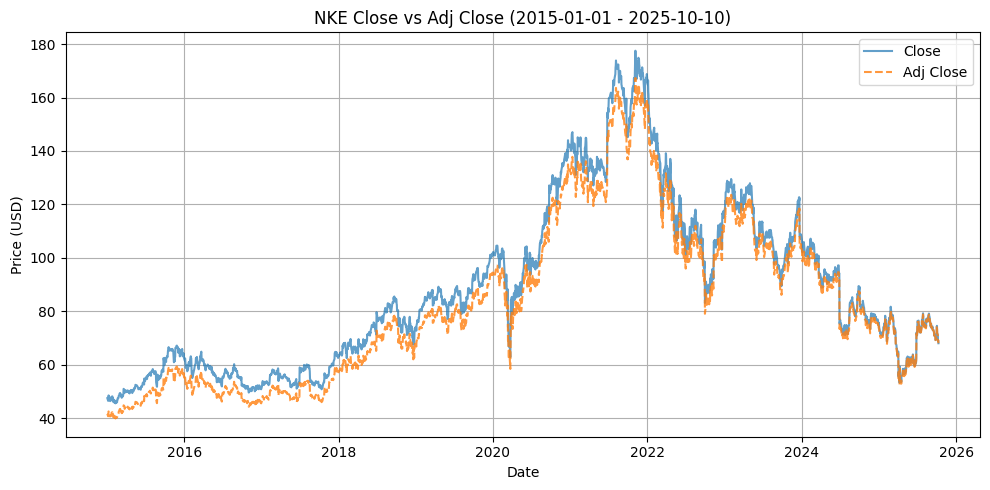

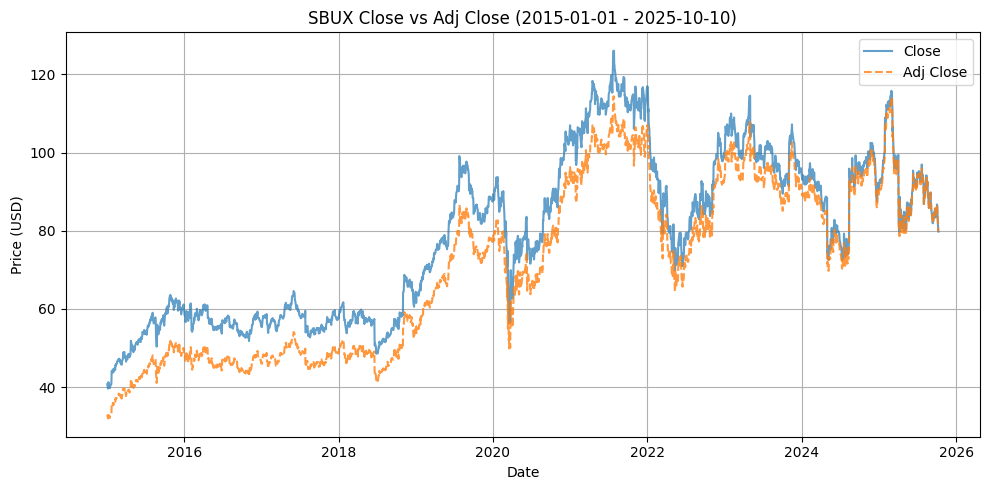

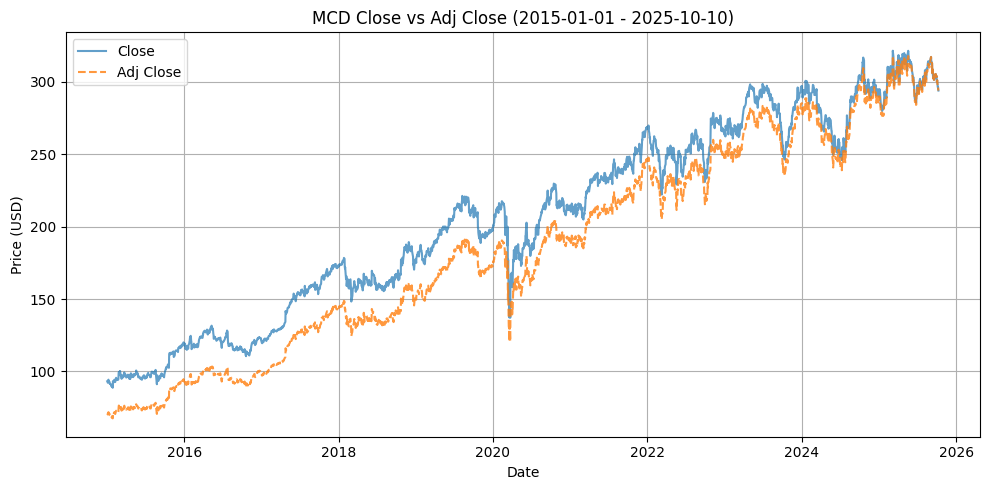

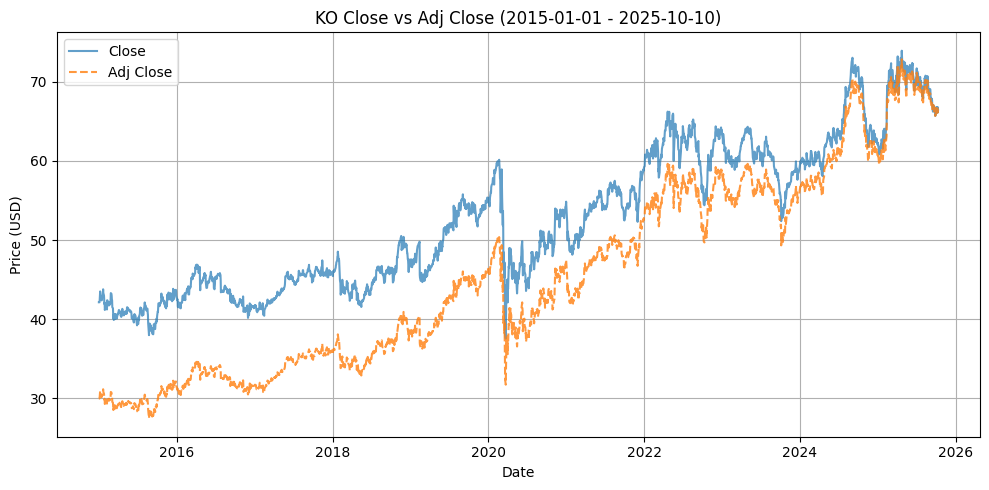

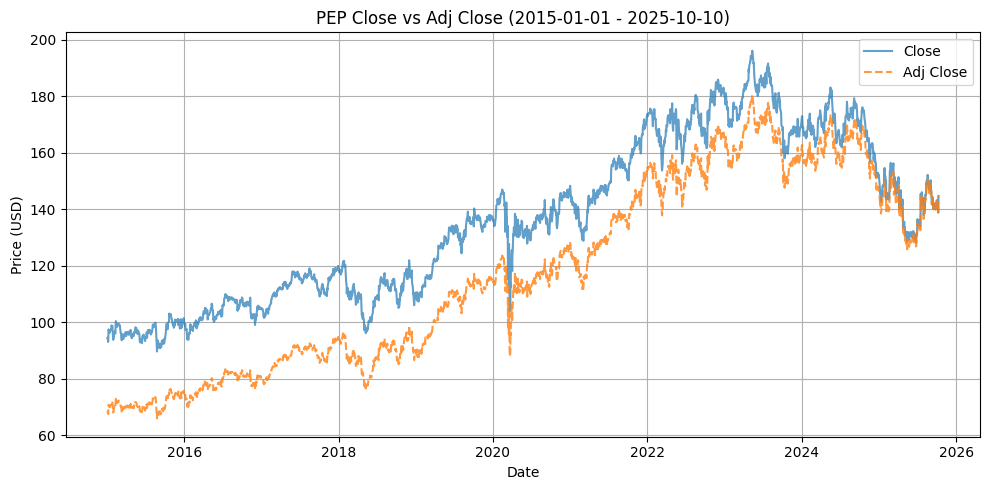

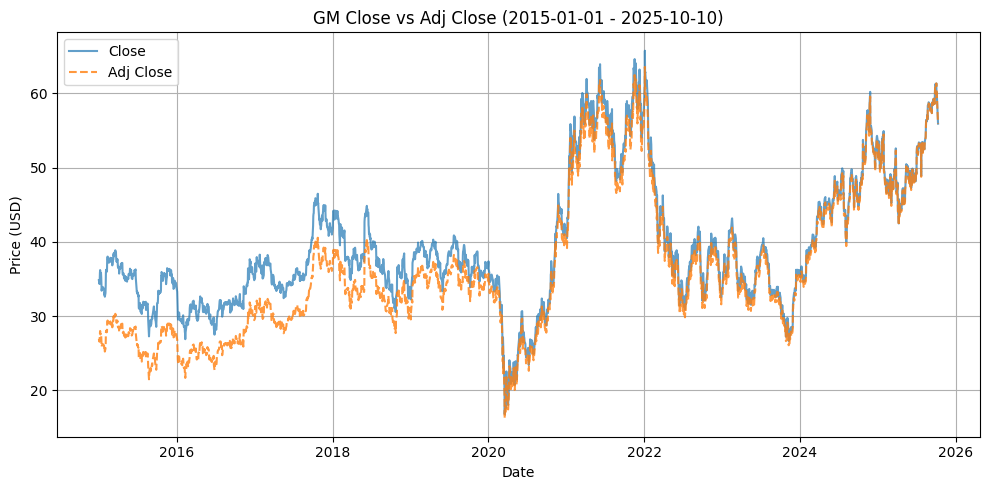

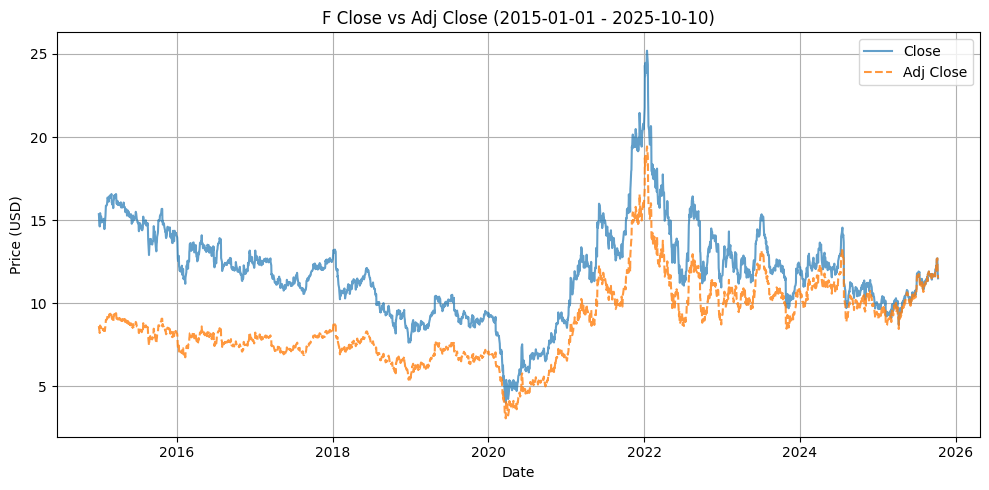

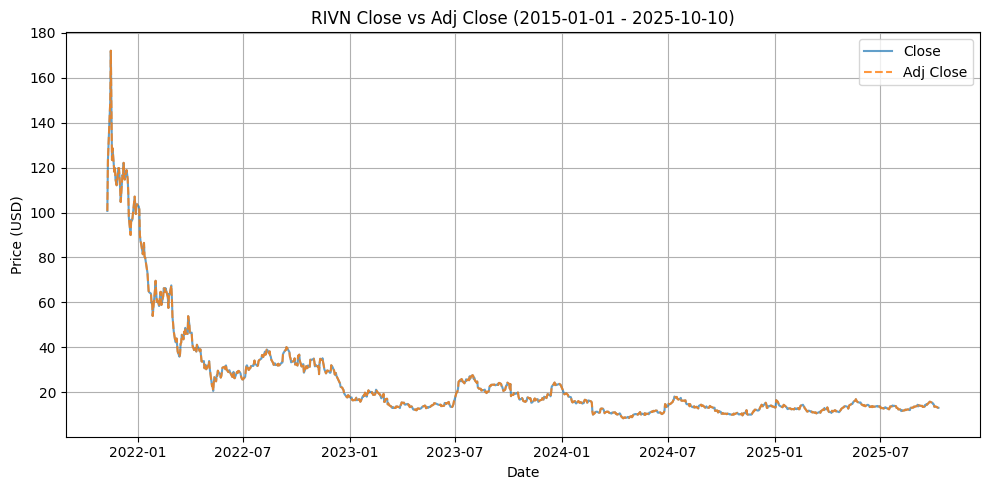

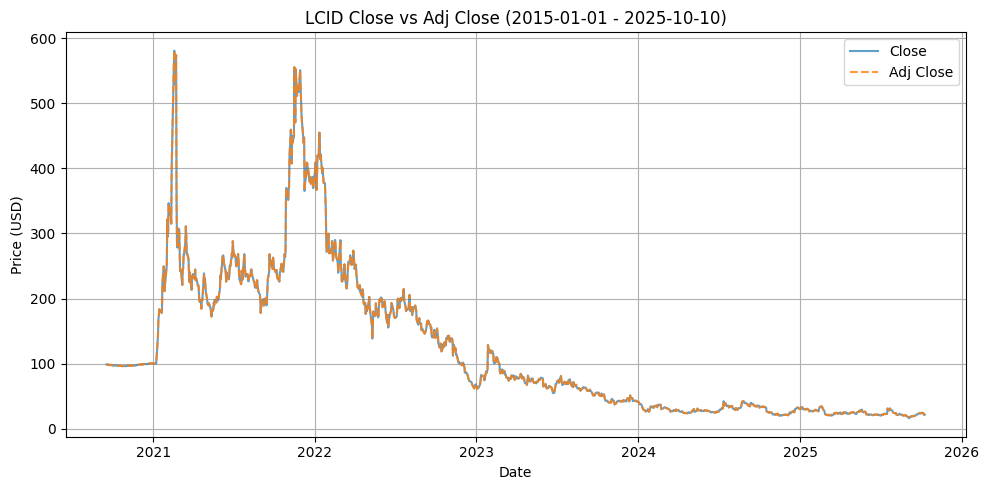

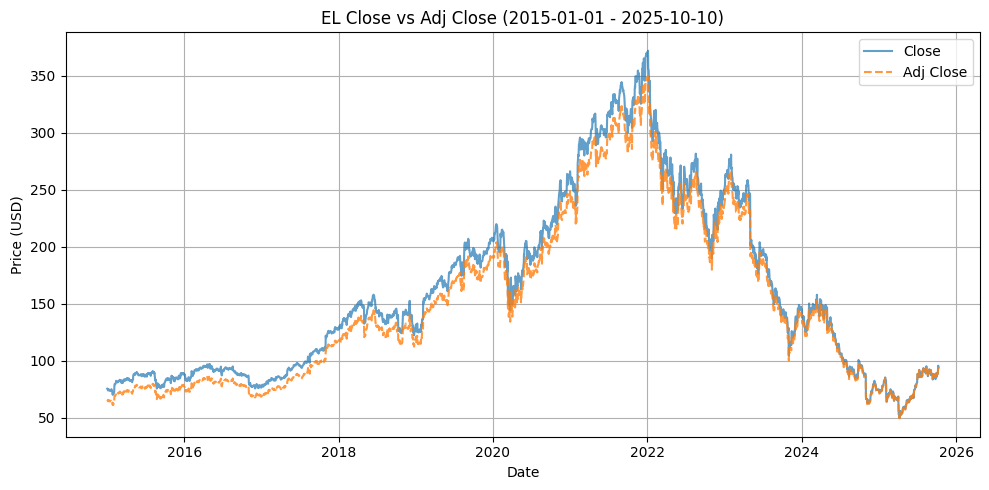

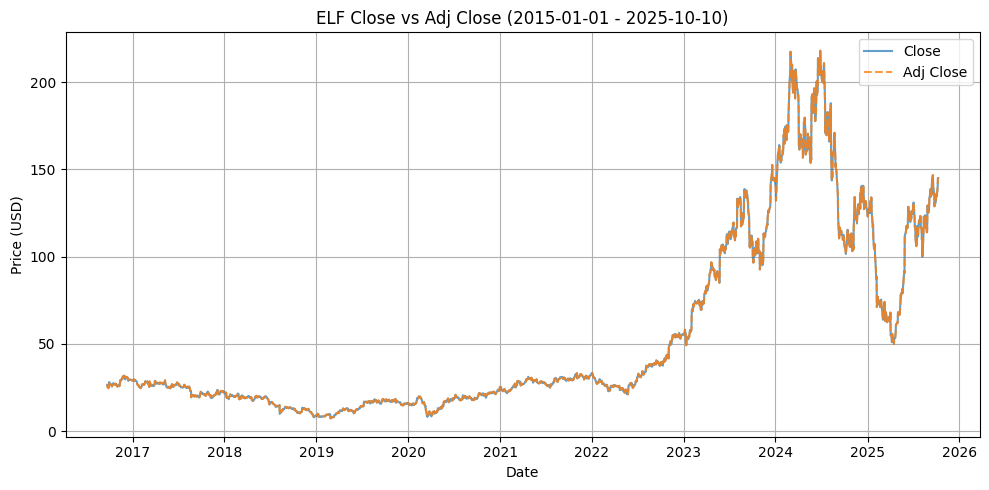

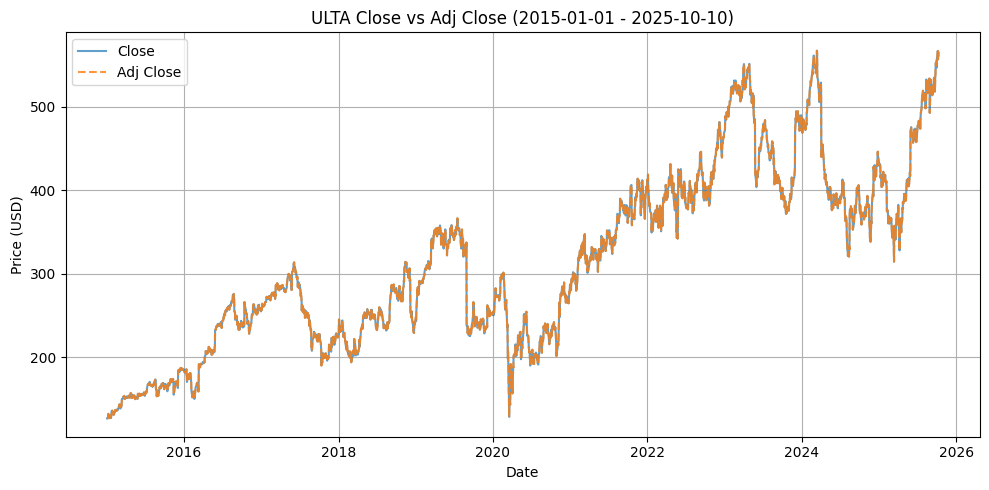

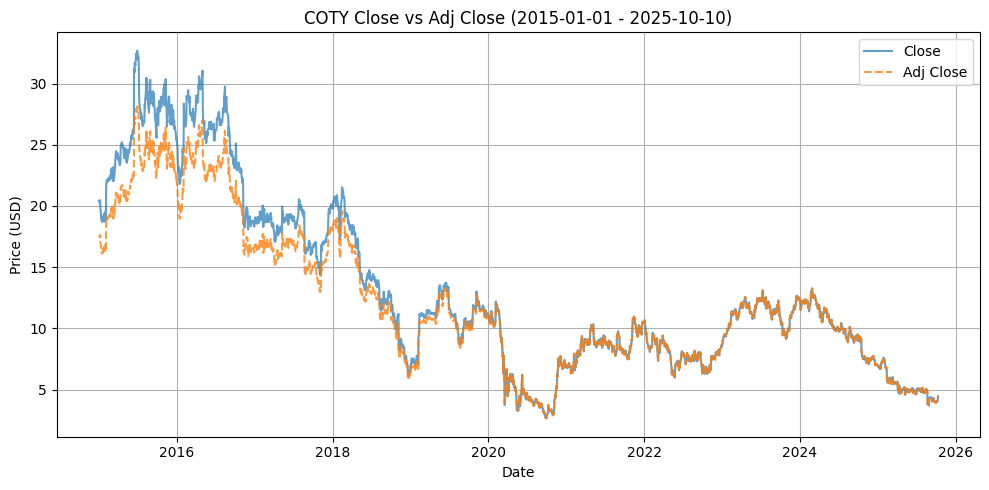

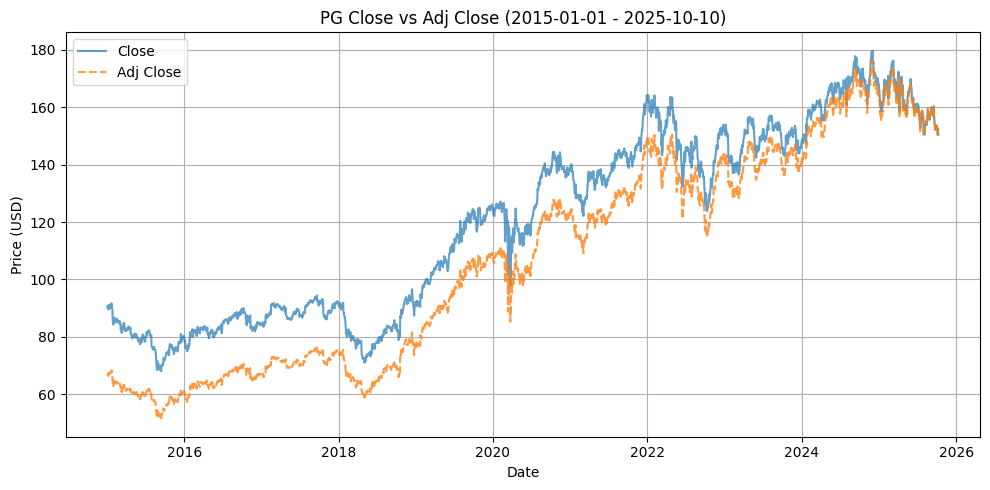

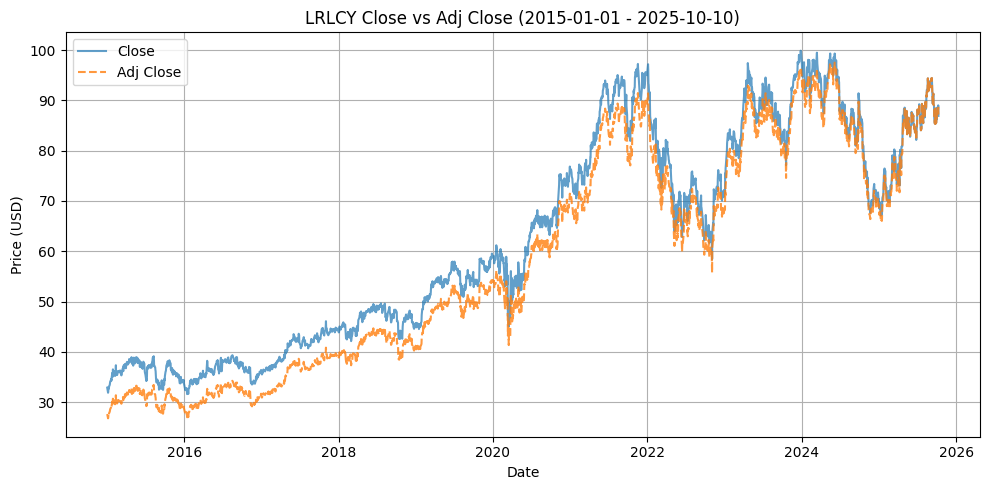

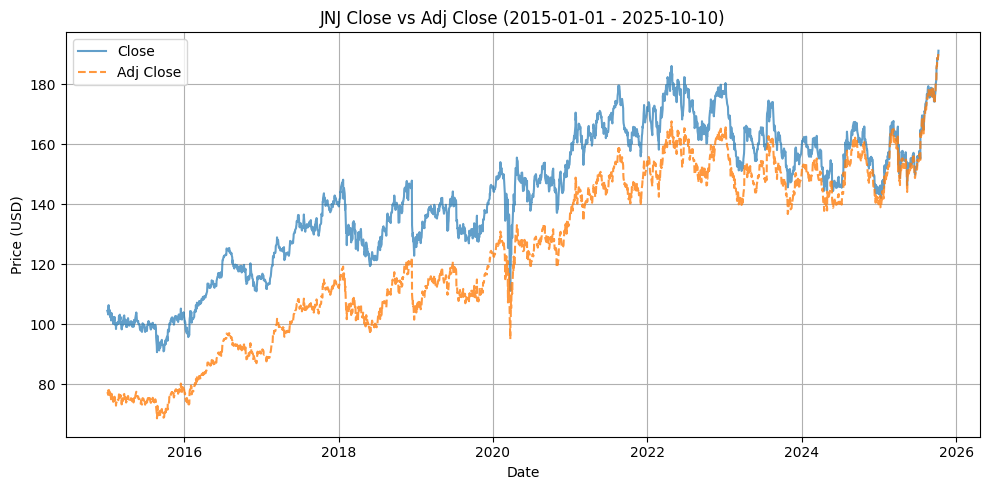

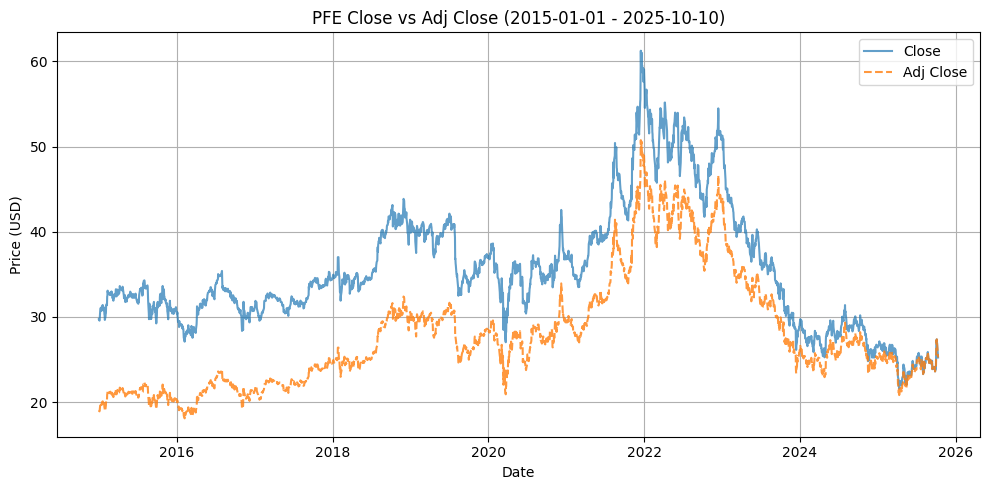

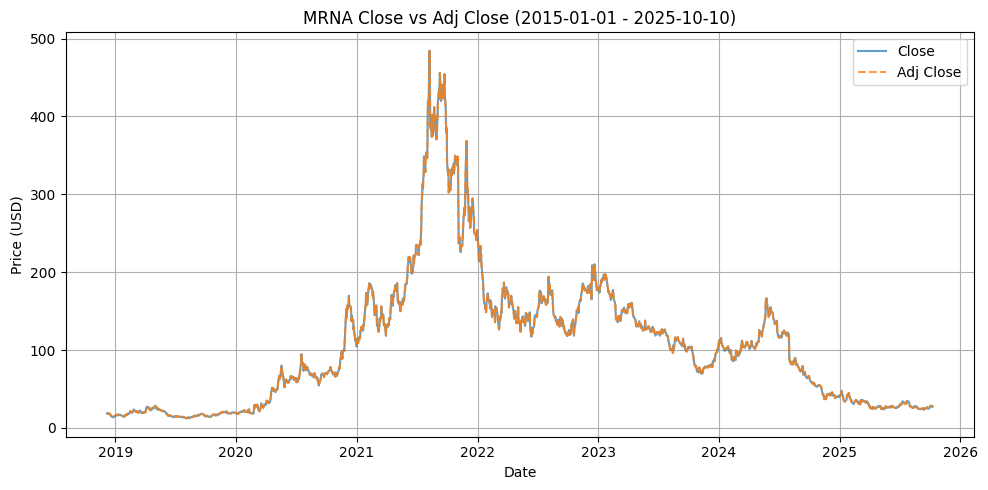

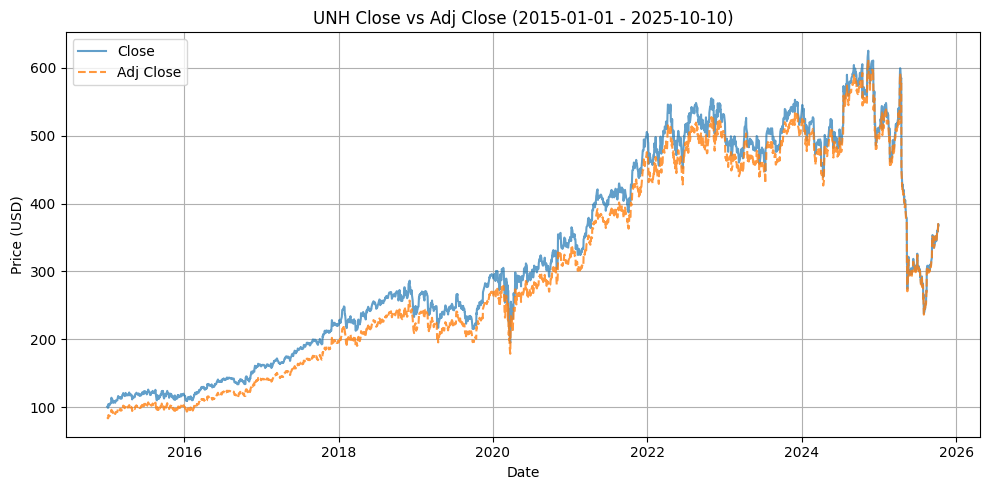

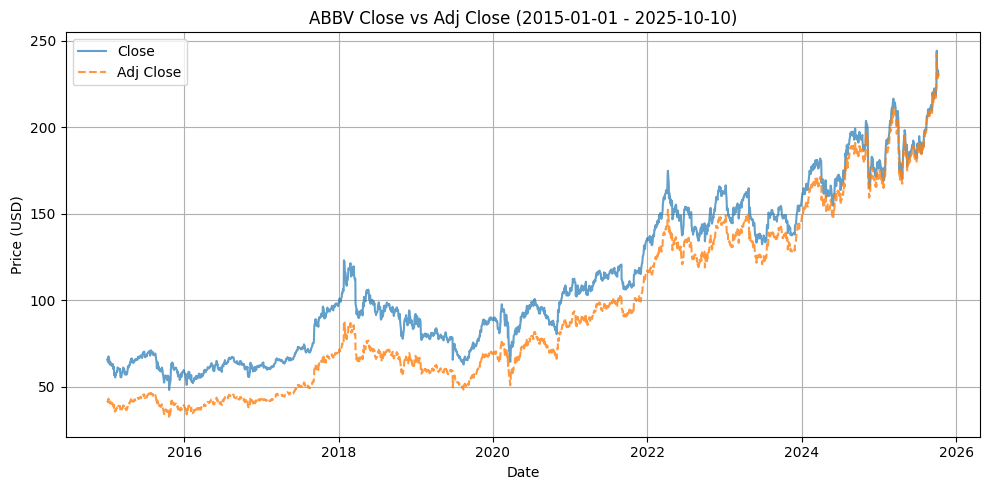

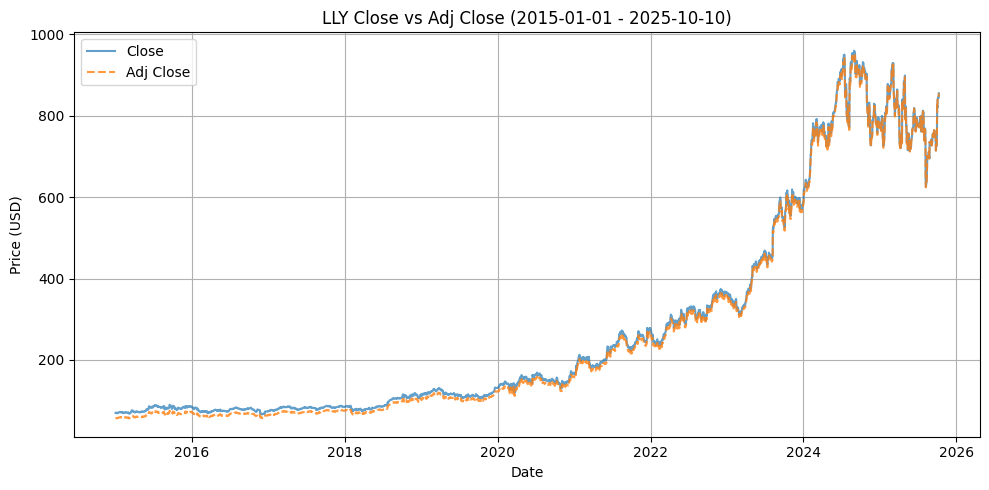

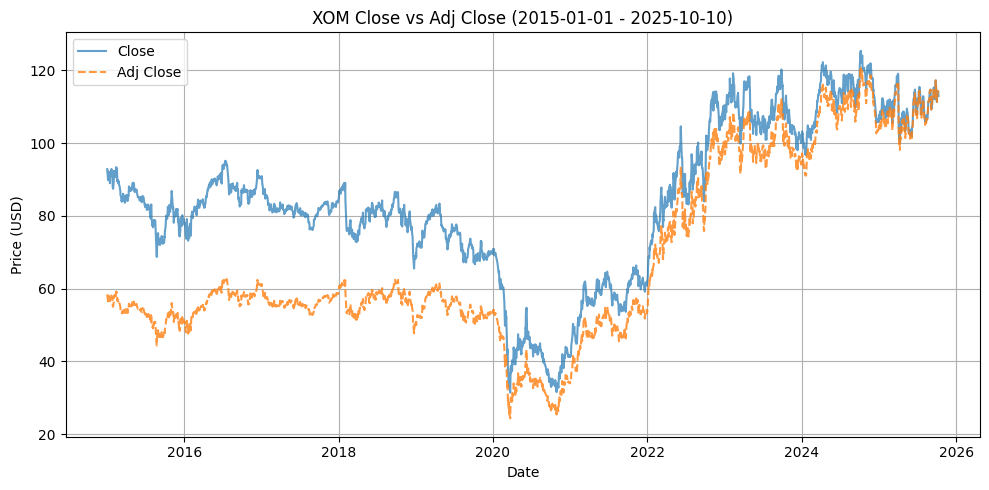

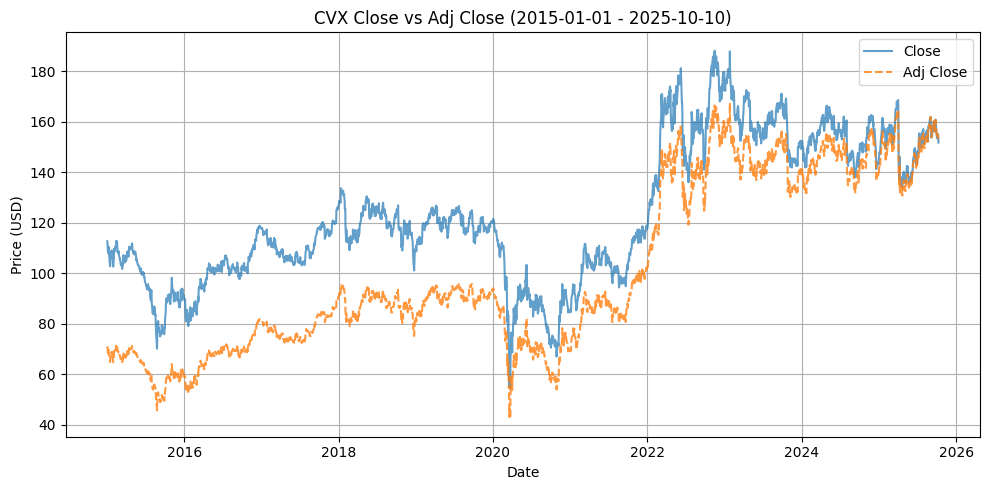

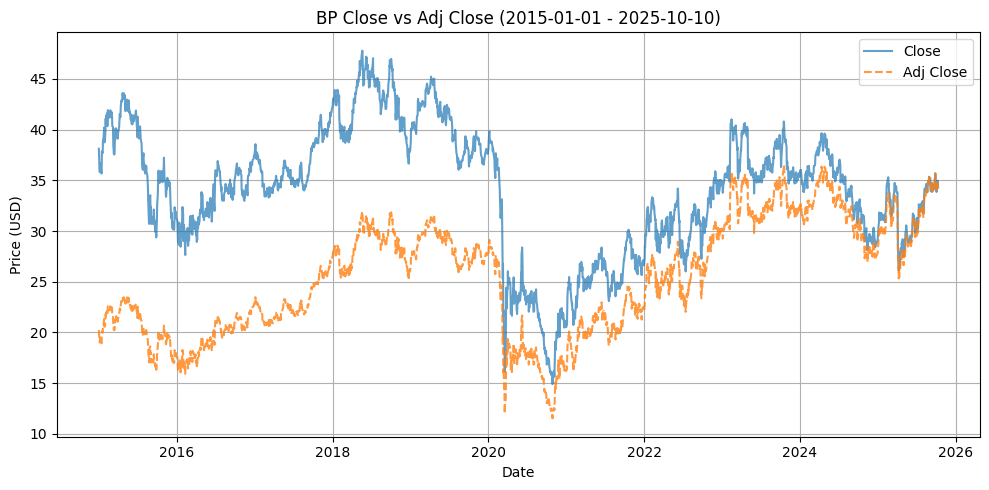

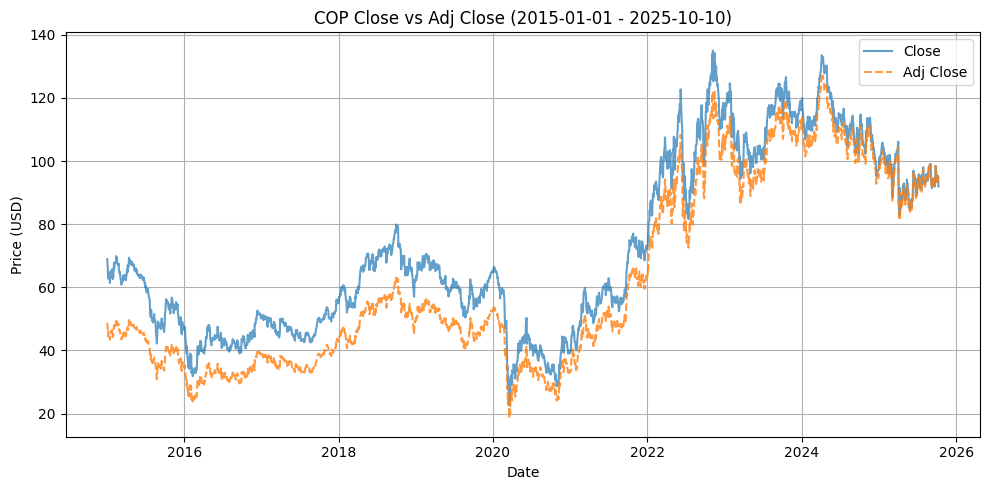

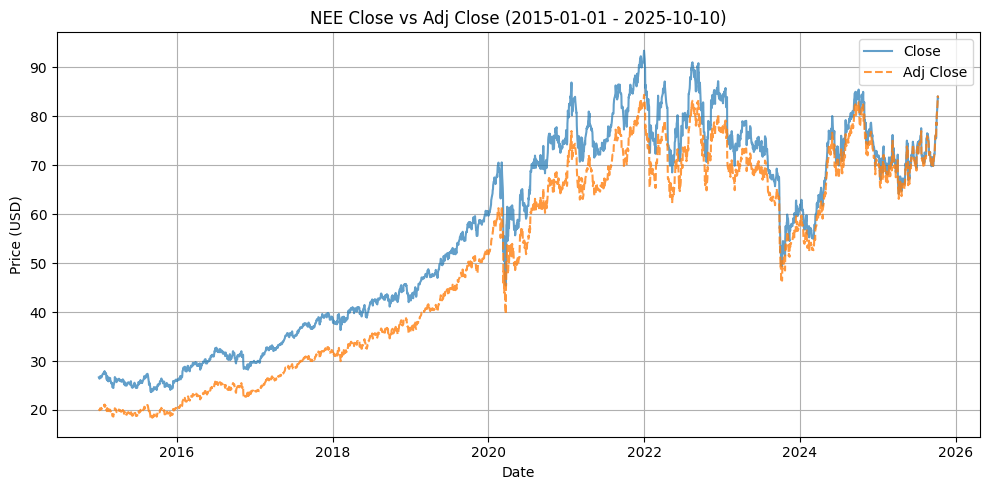

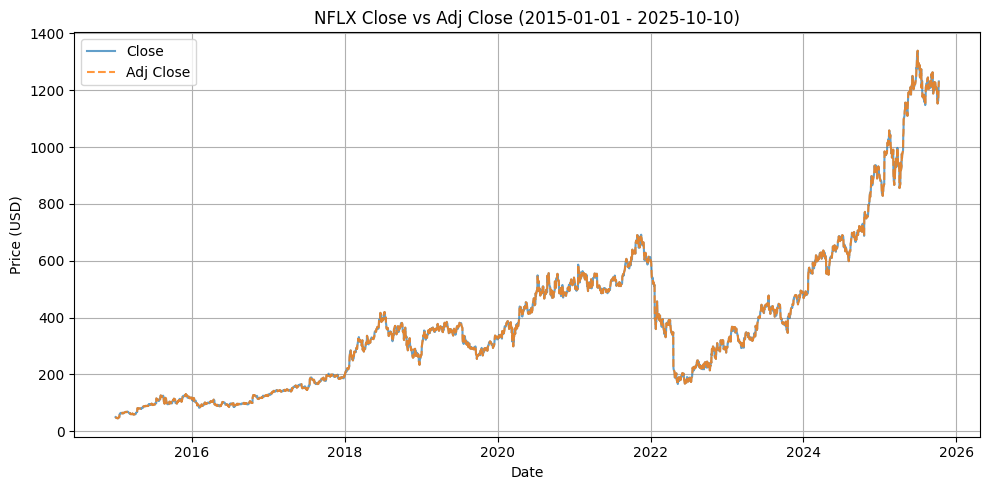

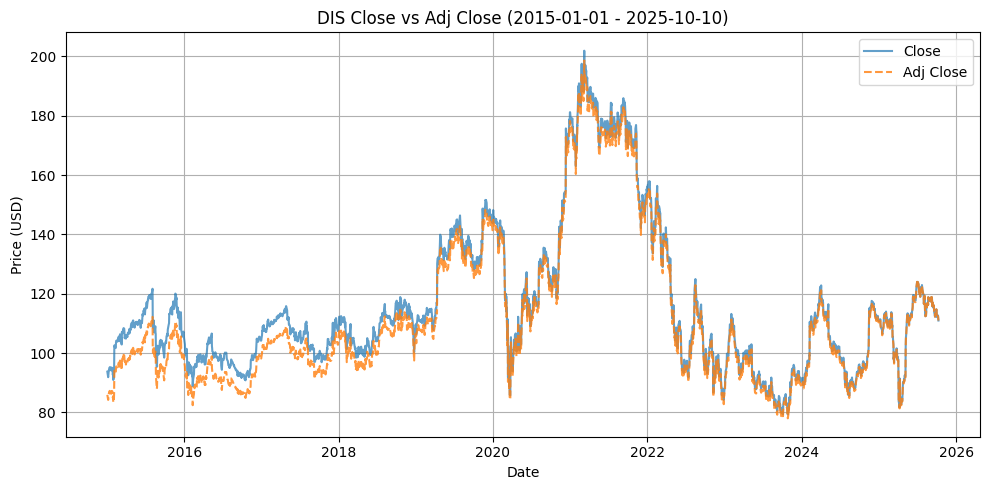

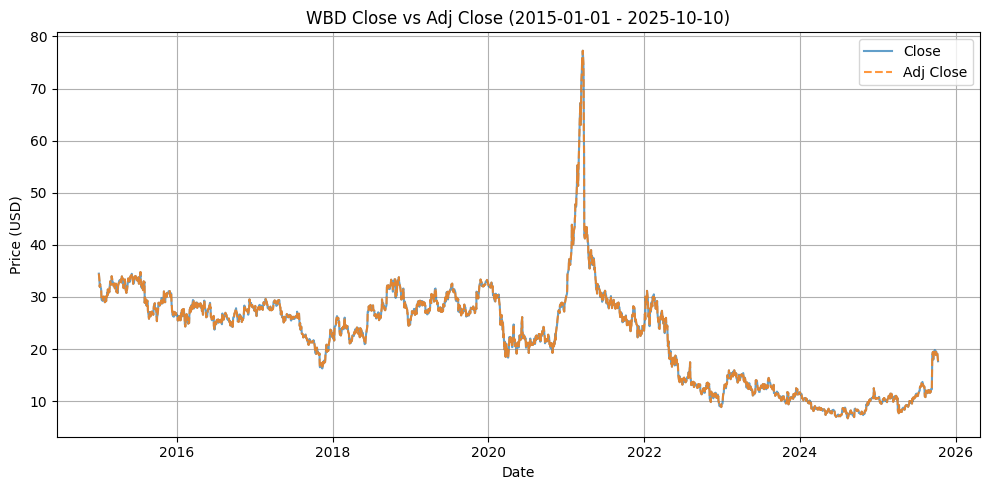

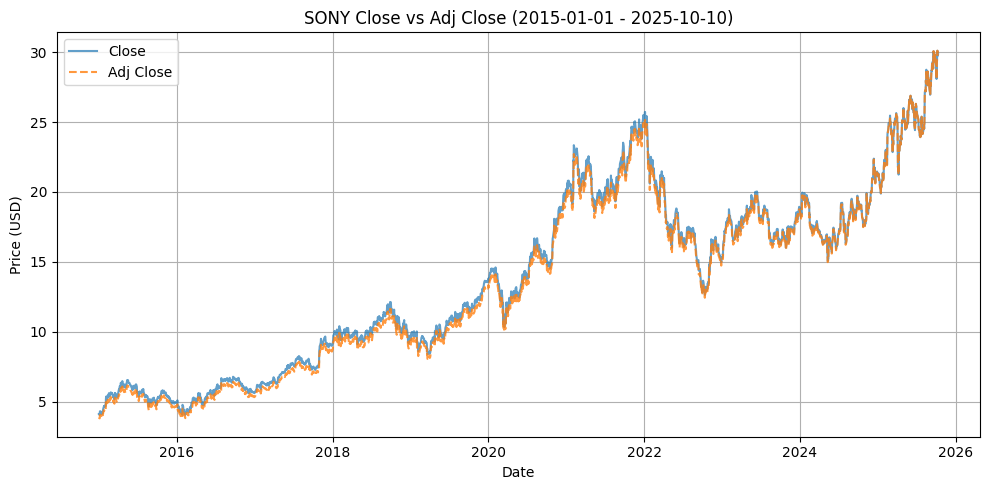

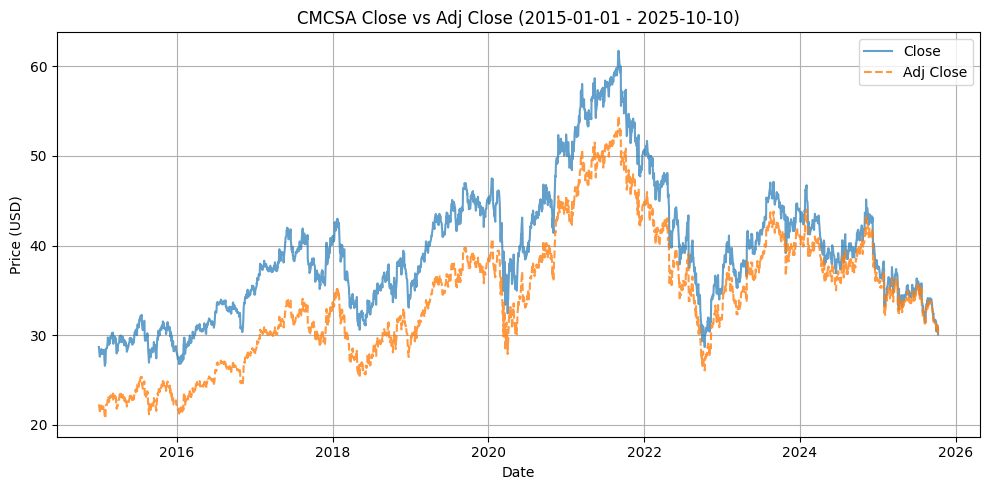

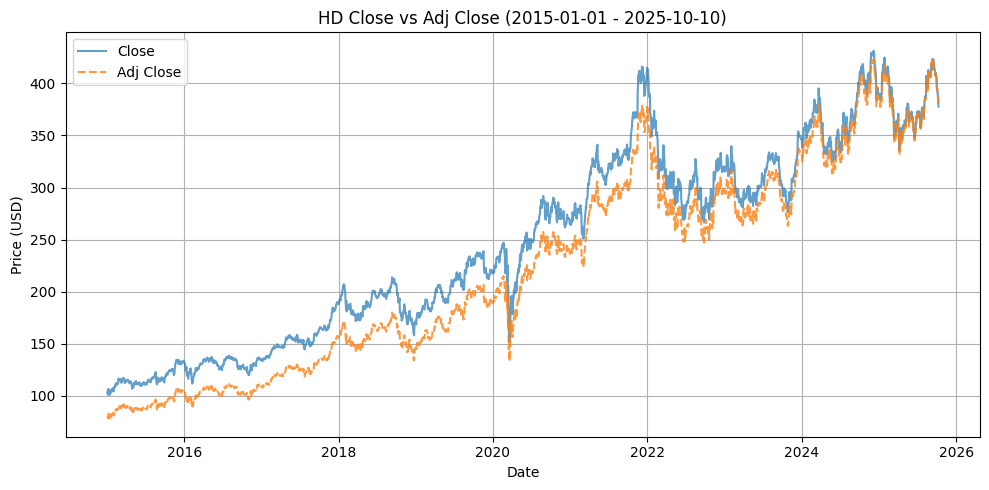

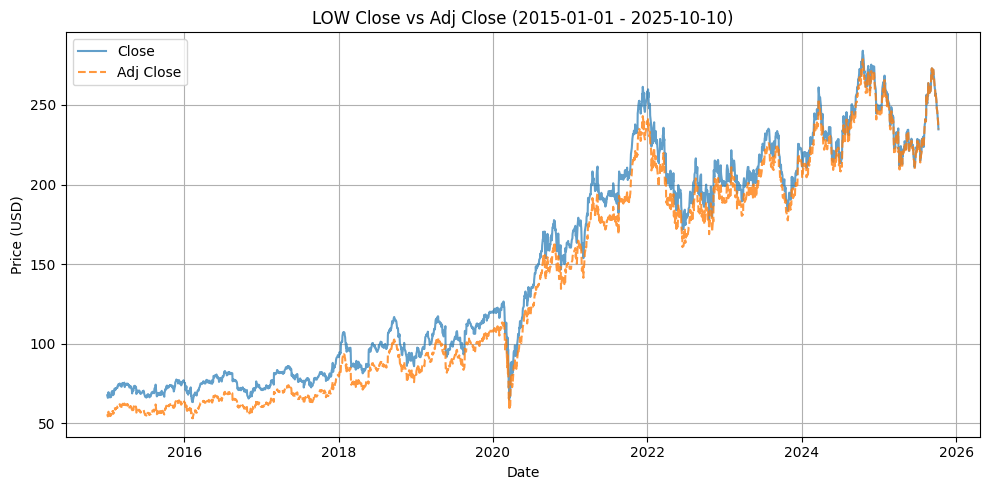

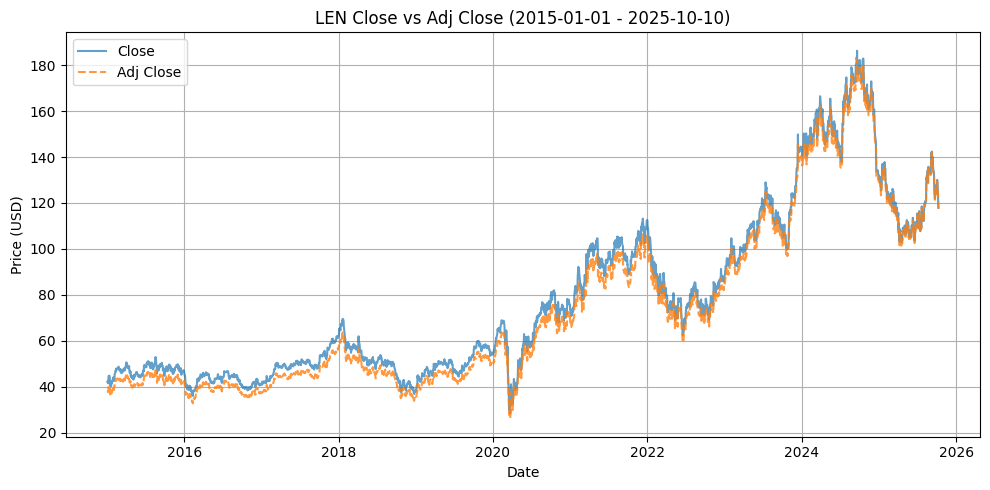

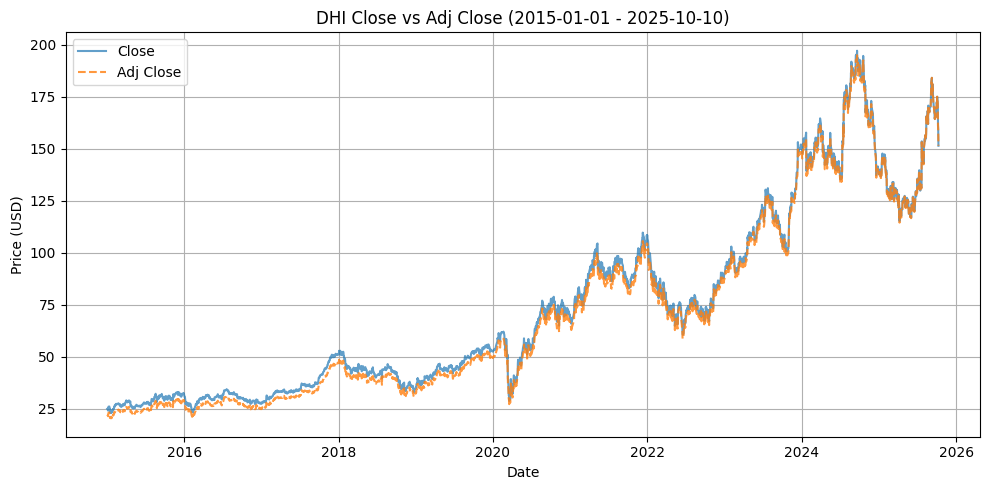

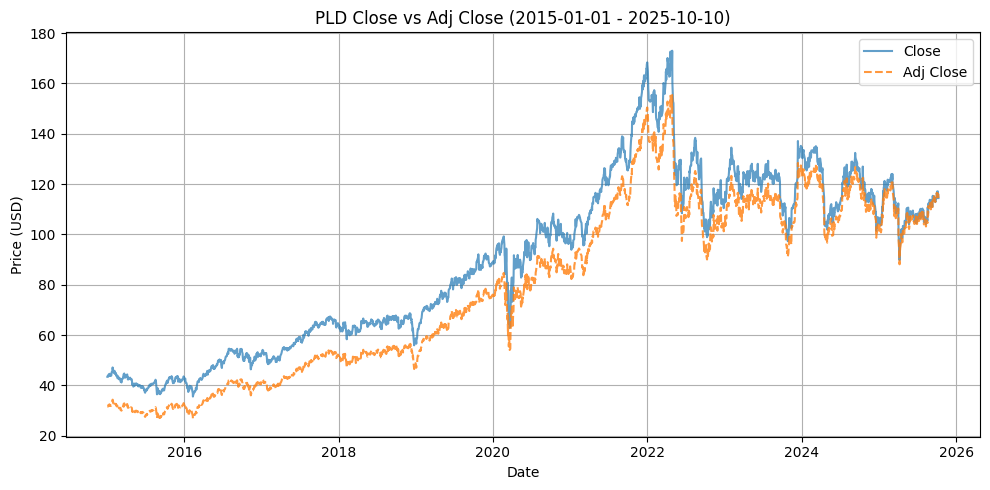

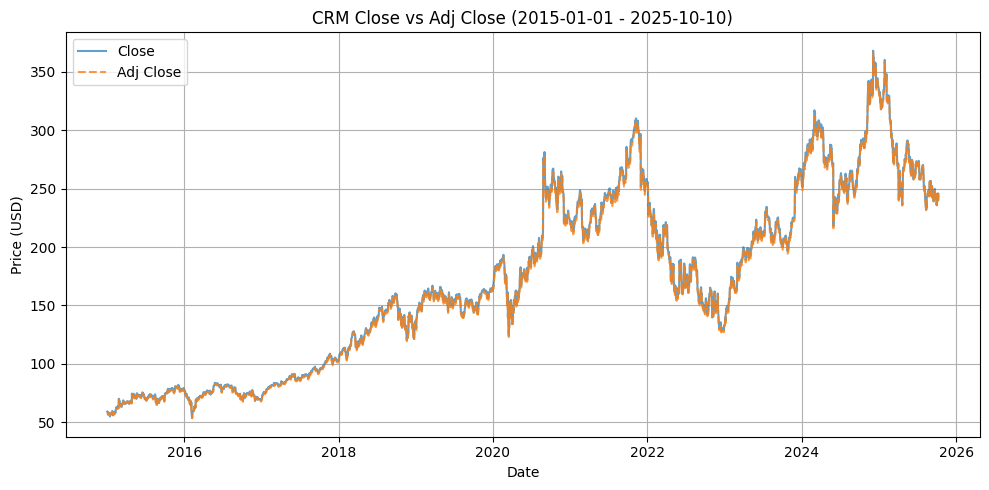

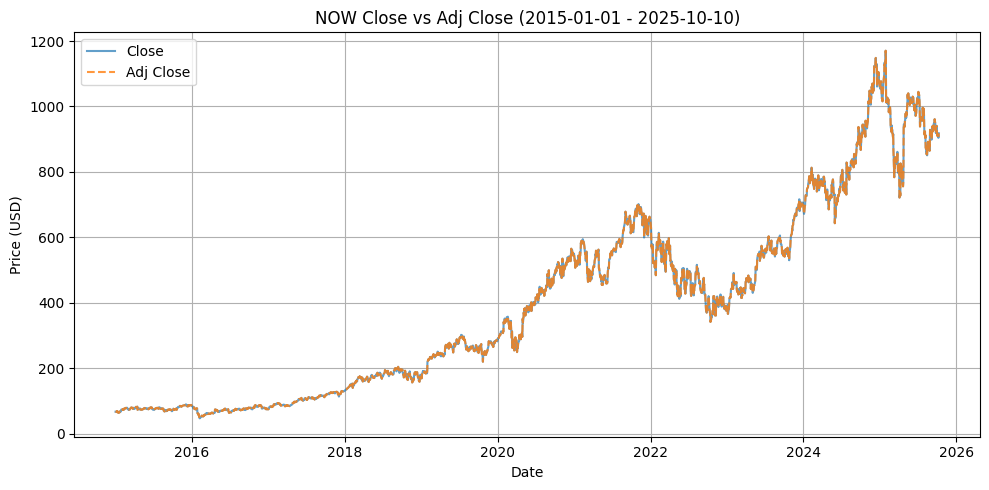

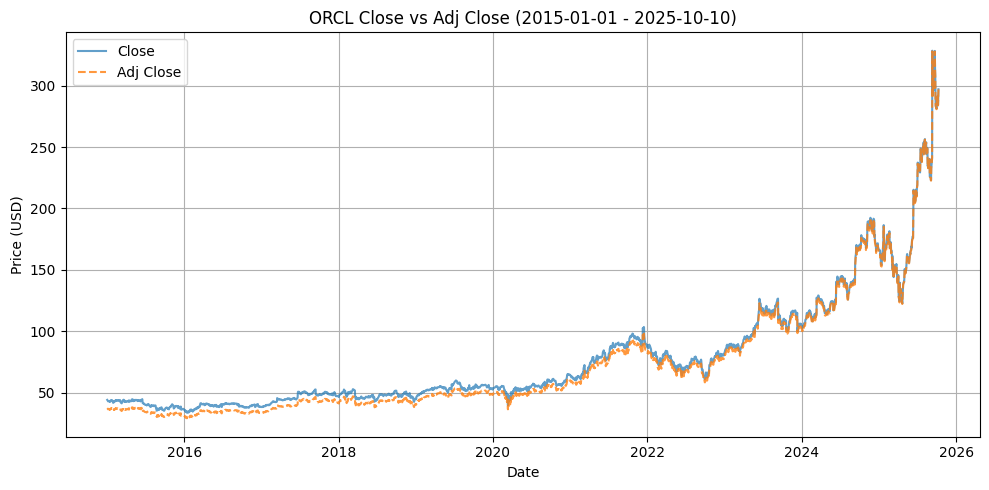

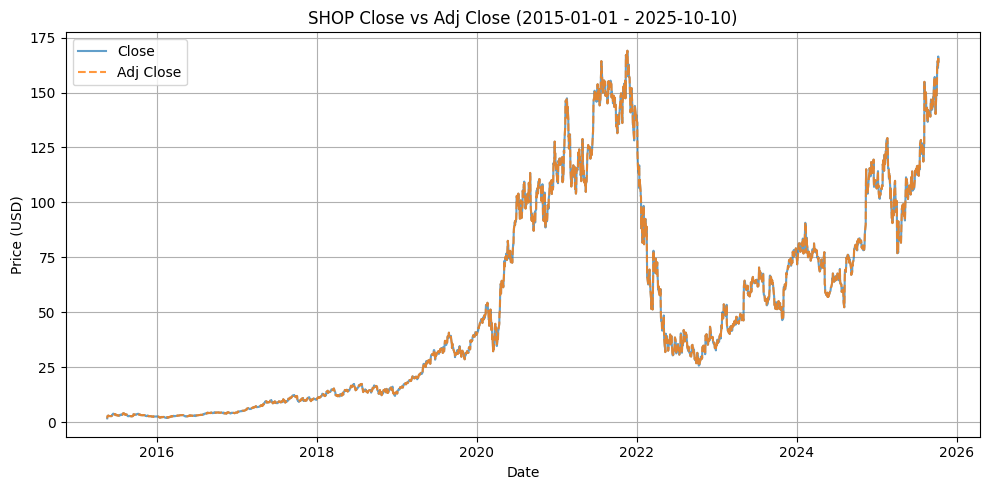

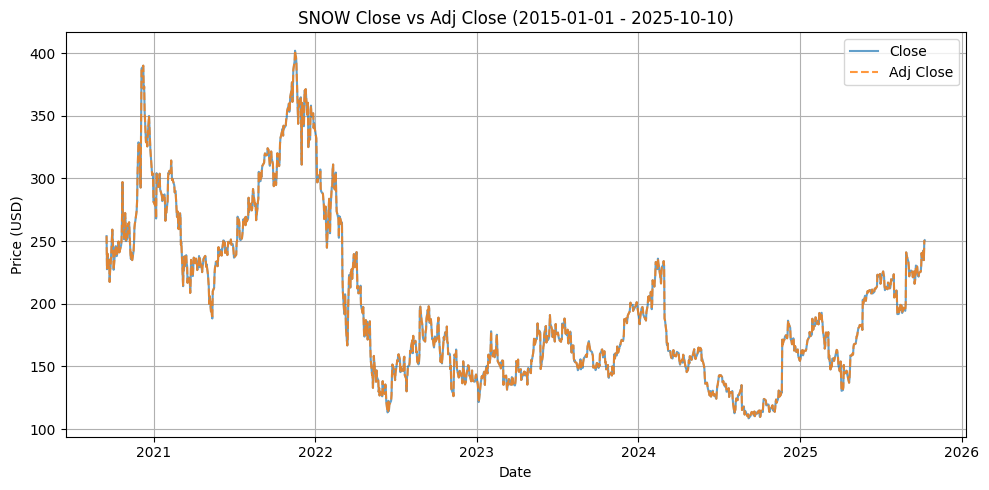

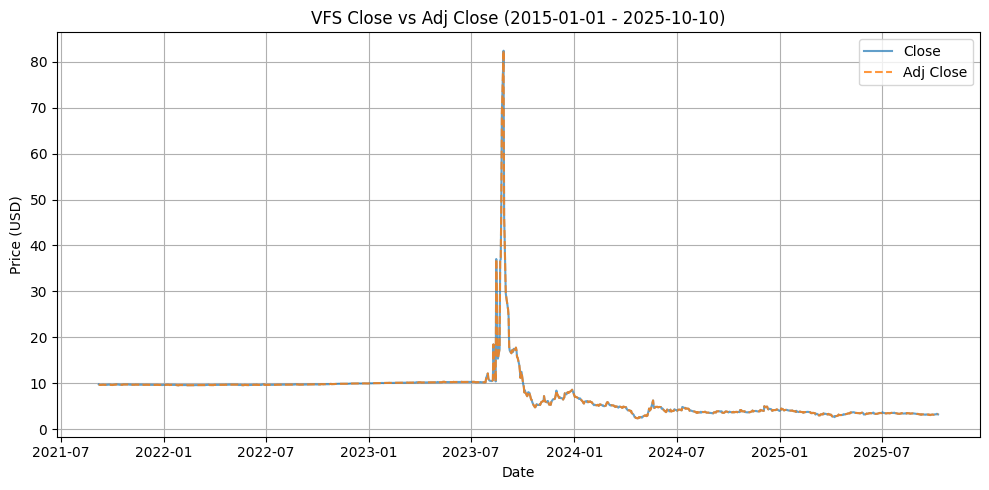

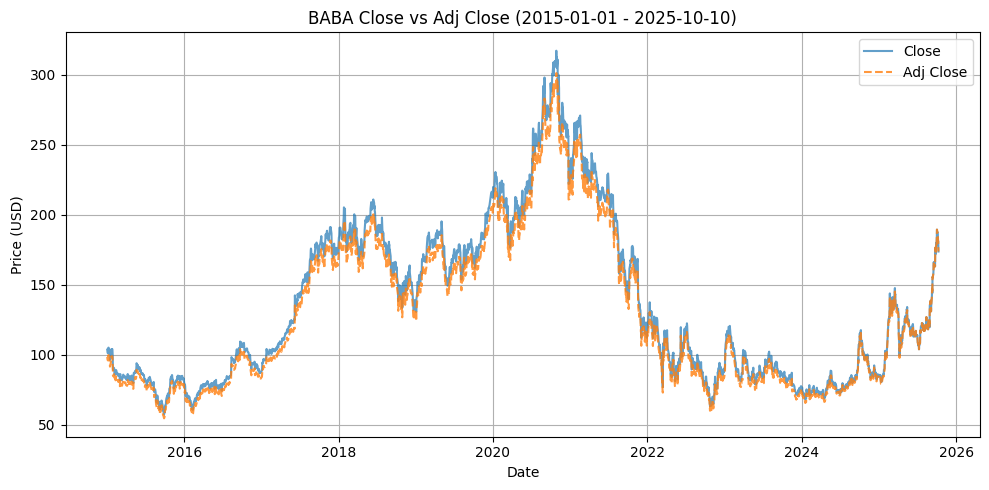

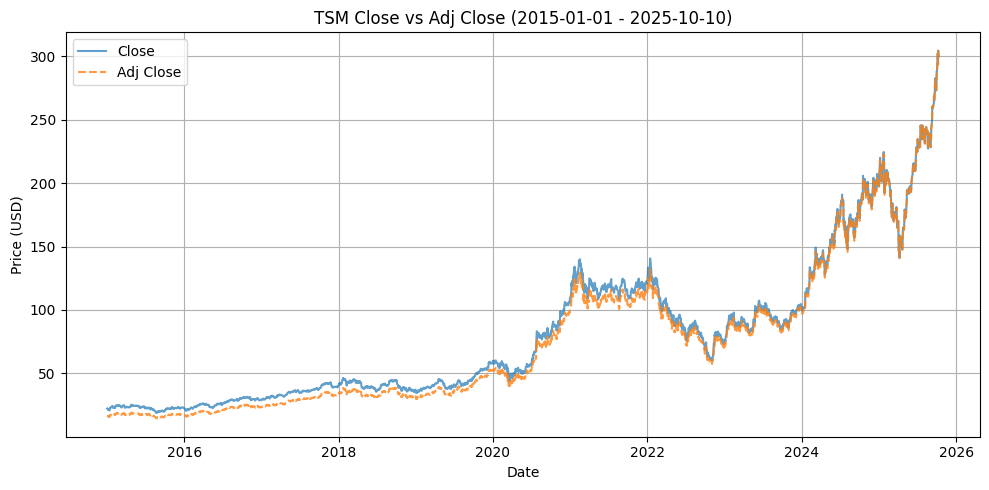

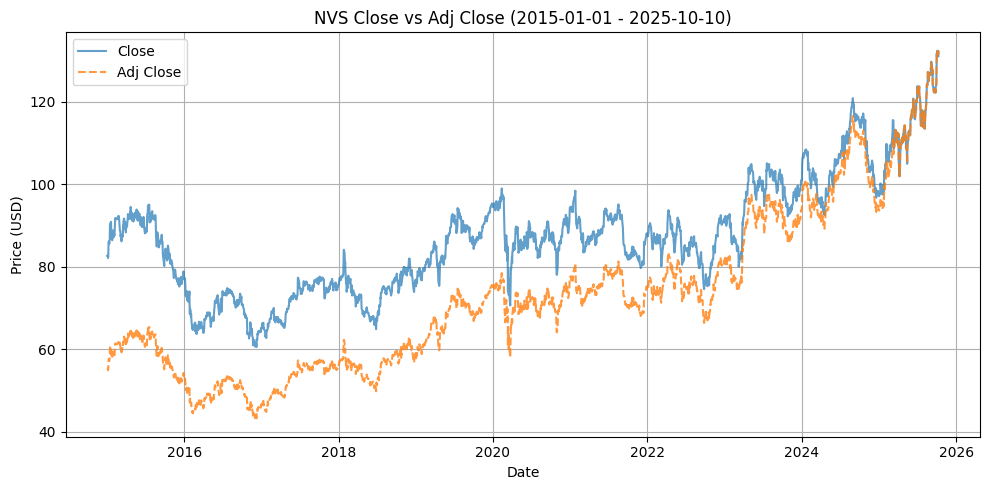

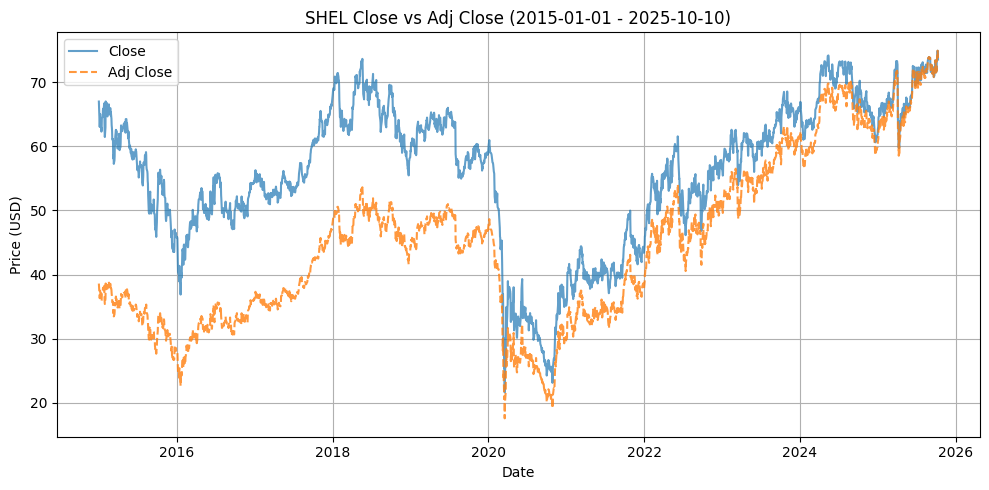

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import os

# Tạo thư mục lưu hình nếu chưa có
os.makedirs("Stock_Plots", exist_ok=True)

# Danh sách mã cổ phiếu
symbols = ['AAPL', 'MSFT', 'GOOG', 'META', 'AMZN', 'NVDA', 'TSLA', 'AMD', 'INTC', 'ADBE',
           'JPM', 'BAC', 'GS', 'MS', 'V', 'MA', 'PYPL',
           'WMT', 'TGT', 'COST', 'NKE', 'SBUX', 'MCD', 'KO', 'PEP',
           'GM', 'F', 'RIVN', 'LCID',
           'EL', 'ELF', 'ULTA', 'COTY', 'PG', 'LRLCY',
           'JNJ', 'PFE', 'MRNA', 'UNH', 'ABBV', 'LLY',
           'XOM', 'CVX', 'BP', 'COP', 'NEE',
           'NFLX', 'DIS', 'WBD', 'SONY', 'CMCSA',
           'HD', 'LOW', 'LEN', 'DHI', 'PLD',
           'CRM', 'NOW', 'ORCL', 'SHOP', 'SNOW',
           'VFS', 'BABA', 'TSM', 'NVS', 'SHEL']

start_date = '2015-01-01'
end_date = '2025-10-10'

file_path = "Stocks_MultiSheet_withPlots.xlsx"
summary_data = []

with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
    for sym in symbols:
        df = yf.download(sym, start=start_date, end=end_date, progress=False, auto_adjust=False)

        if not df.empty:
            # Giữ lại cột Adj Close (giá đã điều chỉnh)
            df = df[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]

            # Ghi dữ liệu vào sheet riêng
            df.to_excel(writer, sheet_name=sym)

            # Tạo summary cho sheet này
            increase_pct = (df['Adj Close'].iloc[-1] - df['Adj Close'].iloc[0]) / df['Adj Close'].iloc[0] * 100
            summary = {
                'Symbol': sym,
                'Adj Close Mean': df['Adj Close'].mean(),
                'Adj Close Max': df['Adj Close'].max(),
                'Adj Close Min': df['Adj Close'].min(),
                'Adj Close Std': df['Adj Close'].std(),
                'Total Volume': df['Volume'].sum(),
                'Increase (%)': increase_pct
            }
            summary_data.append(summary)

            # Vẽ biểu đồ Close và Adj Close
            plt.figure(figsize=(10,5))
            plt.plot(df.index, df['Close'], label='Close', alpha=0.7)
            plt.plot(df.index, df['Adj Close'], label='Adj Close', linestyle='--', alpha=0.8)
            plt.title(f'{sym} Close vs Adj Close ({start_date} - {end_date})')
            plt.xlabel('Date')
            plt.ylabel('Price (USD)')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()  # Hiển thị trong notebook
            plt.savefig(f'Stock_Plots/{sym}_Close_AdjClose.png')  # Lưu hình
            plt.close()

    # Ghi summary vào sheet tổng hợp
    if summary_data:
        summary_df = pd.DataFrame(summary_data)
        summary_df.to_excel(writer, sheet_name="Summary", index=False)

# Tải file Excel về máy
files.download(file_path)
